# 3. Model Architecture Comparison

**Goal**: Compare 8 CNN architectures on the Spanish FetalPlanes DB across:
- Classification accuracy, AUC, F1
- Inference speed (FPS) - critical for video-rate deployment in African clinics
- Parameter count and model size
- Training stability (loss curves)

**Models**: MobileNetV2, MobileNetV3-Small, EfficientNet-B0, EfficientNet-B2, ResNet50, DenseNet169, Xception, ConvNeXt-Tiny

**Selection criterion**: Best trade-off between F1 macro score and FPS >= 15 (real-time threshold for video).


In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/OBS_Ultrasound_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("OBS_Ultrasound_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# Download datasets
!bash scripts/download_data.sh

In [5]:
import torch
import yaml
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.models import build_model, benchmark_fps, count_parameters, SUPPORTED_MODELS
from src.data import FetalDataset, build_dataloaders, build_transforms, build_preprocessing_pipeline, CLASSES
from src.evaluation import evaluate_on_domain
from src.utils import set_seed

set_seed(42)
sns.set_style("whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

with open("configs/base_config.yaml") as f:
    cfg = yaml.safe_load(f)


Device: cuda


## 1. FPS & Parameter Benchmark (no training needed)

In [6]:
bench_results = []
image_size = cfg["data"]["image_size"]

for model_key in SUPPORTED_MODELS:
    print(f"Benchmarking {model_key}...", end=" ")
    try:
        model = build_model(model_key, num_classes=4, pretrained=False)
        params = count_parameters(model)
        fps_info = benchmark_fps(model, image_size=image_size, device=device,
                                  warmup_runs=5, eval_runs=50)
        bench_results.append({
            "model": model_key,
            "params_M": round(params["total"] / 1e6, 1),
            **fps_info,
        })
        print(f"FPS={fps_info['fps']:.1f}  params={params['total']/1e6:.1f}M")
        del model
        if device == "cuda": torch.cuda.empty_cache()
    except Exception as e:
        print(f"FAILED: {e}")

df_bench = pd.DataFrame(bench_results).sort_values("fps", ascending=False)
print("\n", df_bench[["model","params_M","fps","latency_ms_mean"]].to_string(index=False))


Benchmarking mobilenetv2... FPS=192.8  params=2.2M
Benchmarking mobilenetv3_small... FPS=192.0  params=1.5M
Benchmarking efficientnet_b0... FPS=130.3  params=4.0M
Benchmarking efficientnet_b2... FPS=89.2  params=7.7M
Benchmarking resnet50... FPS=153.6  params=23.5M
Benchmarking densenet169... FPS=47.6  params=12.5M
Benchmarking xception... 

/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


FPS=184.9  params=20.8M
Benchmarking convnext_tiny... FPS=130.8  params=27.8M

             model  params_M   fps  latency_ms_mean
      mobilenetv2       2.2 192.8             5.19
mobilenetv3_small       1.5 192.0             5.21
         xception      20.8 184.9             5.41
         resnet50      23.5 153.6             6.51
    convnext_tiny      27.8 130.8             7.65
  efficientnet_b0       4.0 130.3             7.67
  efficientnet_b2       7.7  89.2            11.21
      densenet169      12.5  47.6            21.00


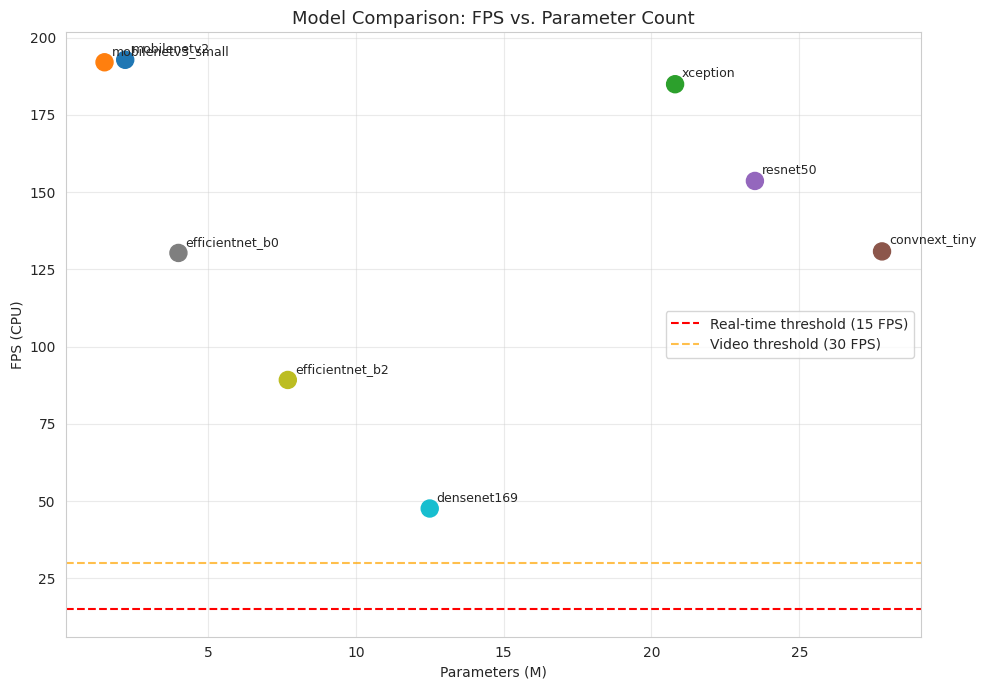

In [7]:
# Visualise FPS vs Parameters (Pareto frontier)
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(df_bench["params_M"], df_bench["fps"],
                     s=150, c=range(len(df_bench)), cmap="tab10", zorder=3)
for _, row in df_bench.iterrows():
    ax.annotate(row["model"], (row["params_M"], row["fps"]),
                xytext=(5,5), textcoords="offset points", fontsize=9)
ax.axhline(y=15, color="red", ls="--", label="Real-time threshold (15 FPS)")
ax.axhline(y=30, color="orange", ls="--", label="Video threshold (30 FPS)", alpha=0.7)
ax.set_xlabel("Parameters (M)"); ax.set_ylabel("FPS (CPU)")
ax.set_title("Model Comparison: FPS vs. Parameter Count", fontsize=13)
ax.legend(); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("docs/model_fps_params.png", dpi=150)
plt.show()


## 2. Train All Models on Spanish Data

In [ ]:
# Optional: Weights & Biases tracking. Provide WANDB_API_KEY as an environment
# variable (or a Kaggle secret named WANDB). Without it, pass tracker="none".
import os
if "WANDB_API_KEY" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB")
    except Exception:
        print("WANDB_API_KEY not set; W&B logging will be unavailable.")

In [ ]:

MODELS_TO_COMPARE = list(SUPPORTED_MODELS.keys())
# Uncomment to run only lightweight models for quick testing:
# MODELS_TO_COMPARE = ["mobilenetv3_small", "efficientnet_b0", "resnet50", "densenet169"]

for model_key in MODELS_TO_COMPARE:
    print(f"\n{'='*60}")
    print(f"Training: {model_key}")
    print(f"{'='*60}")
    !python scripts/train.py \
        --experiment baseline_fetal \
        --model {model_key} \
        --tracker wandb \
        --seed 42



Training: mobilenetv2
18:44:09 | INFO     | train | Running experiment  : baseline_fetal
18:44:09 | INFO     | train | Description         : Train and evaluate on Fetal DB only (pre-split train/val/test)
18:44:09 | INFO     | train | Dataset sizes - train: 5121  val: 2008
model.safetensors: 100%|###################| 14.2M/14.2M [00:00<00:00, 22.4MB/s]
18:44:10 | INFO     | train | Parameters - total: 2,228,996  trainable: 2,228,996
18:44:12 | INFO     | src.training.trainer | W&B tracker initialised
18:45:26 | INFO     | src.training.trainer | Epoch   1/50 | train_loss=1.3503 | val_loss=0.3156 | val_acc=0.9044 | val_auc=0.9872 | 73.2s
18:46:23 | INFO     | src.training.trainer | Epoch   2/50 | train_loss=0.4127 | val_loss=0.2992 | val_acc=0.9158 | val_auc=0.9913 | 57.0s
18:47:19 | INFO     | src.training.trainer | Epoch   3/50 | train_loss=0.2667 | val_loss=0.2468 | val_acc=0.9382 | val_auc=0.9939 | 56.0s
18:48:14 | INFO     | src.training.trainer | Epoch   4/50 | train_loss=0.2173 | 

## 3. Collect & Compare Training Results

In [10]:
# Load all training results from checkpoint history files
ckpt_root = Path("checkpoints")
all_results = []

for model_key in MODELS_TO_COMPARE:
    history_path = ckpt_root / f"baseline_fetal_{model_key}" / "history.json"
    if not history_path.exists():
        history_path = ckpt_root / "baseline_fetal" / "history.json"
    if history_path.exists():
        with open(history_path) as f:
            h = json.load(f)
        all_results.append({
            "model": model_key,
            "best_val_acc": max(h.get("val_acc", [0])),
            "best_val_auc": max(h.get("val_auc", [0])),
            "final_train_loss": h["train_loss"][-1] if h.get("train_loss") else None,
            "epochs": len(h.get("val_acc", [])),
        })

df_perf = pd.DataFrame(all_results)
df_summary = df_bench.merge(df_perf, on="model", how="outer").sort_values("best_val_auc", ascending=False)
print(df_summary[["model","params_M","fps","best_val_acc","best_val_auc"]].to_string(index=False))
df_summary.to_csv("docs/model_comparison_summary.csv", index=False)


            model  params_M   fps  best_val_acc  best_val_auc
    convnext_tiny      27.8 130.8      0.970618      0.994690
  efficientnet_b2       7.7  89.2      0.972610      0.994405
      densenet169      12.5  47.6      0.971116      0.994271
         resnet50      23.5 153.6      0.971614      0.994172
  efficientnet_b0       4.0 130.3      0.972112      0.994025
      mobilenetv2       2.2 192.8      0.972610      0.993872
         xception      20.8 184.9      0.972610      0.992815
mobilenetv3_small       1.5 192.0      0.969622      0.992074


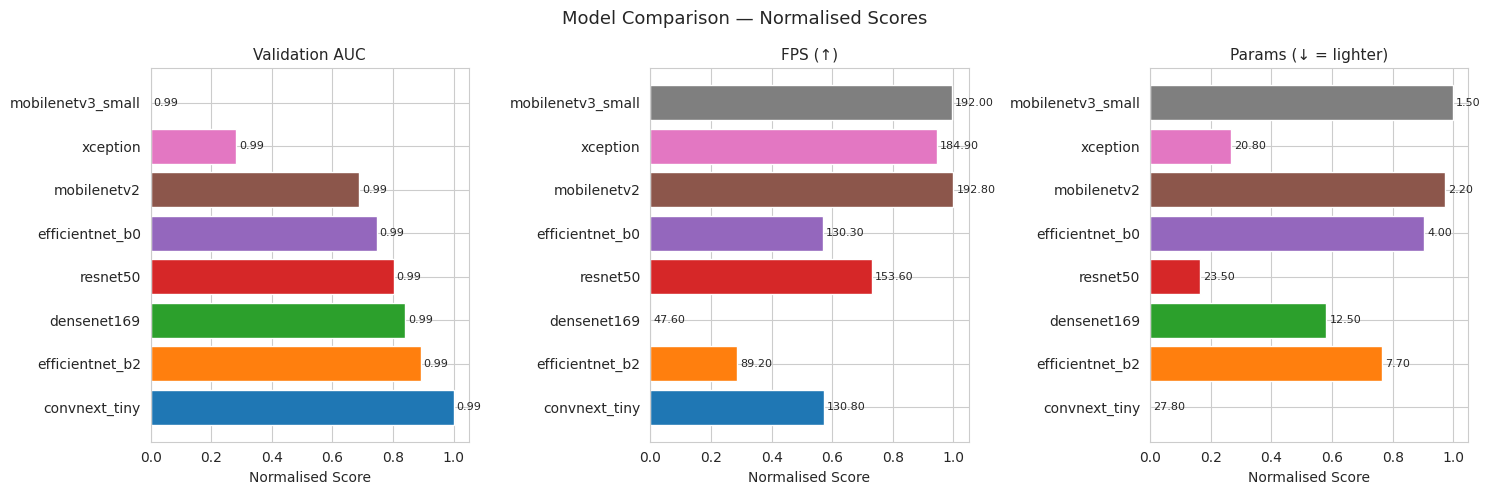

In [11]:
# Radar chart: multi-dimensional comparison

metrics_radar = ["best_val_auc", "fps", "params_M"]  # normalised
df_norm = df_summary.copy()
for m in metrics_radar:
    col = df_norm[m].dropna()
    if m == "params_M":  # lower is better -> invert
        df_norm[m] = 1 - (df_norm[m] - col.min()) / (col.max() - col.min() + 1e-9)
    else:
        df_norm[m] = (df_norm[m] - col.min()) / (col.max() - col.min() + 1e-9)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metric_labels = ["Validation AUC", "FPS ()", "Params (= lighter)"]
palette = plt.cm.tab10.colors

for ax, m, label in zip(axes, metrics_radar, metric_labels):
    vals = df_norm[m].fillna(0).values
    colors = [palette[i % 10] for i in range(len(df_norm))]
    bars = ax.barh(df_norm["model"], vals, color=colors)
    ax.set_xlim(0, 1.05); ax.set_xlabel("Normalised Score")
    ax.set_title(label, fontsize=11)
    for bar, v in zip(bars, df_summary[m].fillna(0)):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f"{v:.2f}", va="center", fontsize=8)

plt.suptitle("Model Comparison - Normalised Scores", fontsize=13)
plt.tight_layout()
plt.savefig("docs/model_radar_comparison.png", dpi=150)
plt.show()
